Вариант: 28, RANDOM_STATE: 1028
Загрузка локальной копии: variant_28.csv

--- Размерность данных ---
Объектов (строк): 1728
Признаков (столбцов): 6

--- Первые 5 строк ---


,buying,maint,doors,persons,lug_boot,safety
0,vhigh,vhigh,2,2,small,low
1,vhigh,vhigh,2,2,small,med
2,vhigh,vhigh,2,2,small,high
3,vhigh,vhigh,2,2,med,low
4,vhigh,vhigh,2,2,med,med



--- Типы данных и пропуски ---


,Тип данных,Уникальных значений,Пропусков,Доля пропусков (%)
buying,str,4,0,0.0
maint,str,4,0,0.0
doors,str,4,0,0.0
persons,str,3,0,0.0
lug_boot,str,3,0,0.0
safety,str,3,0,0.0



--- Распределение целевого класса (y) ---


,Абсолютная частота,Доля (%)
class,,
unacc,1210,70.02
acc,384,22.22
good,69,3.99
vgood,65,3.76


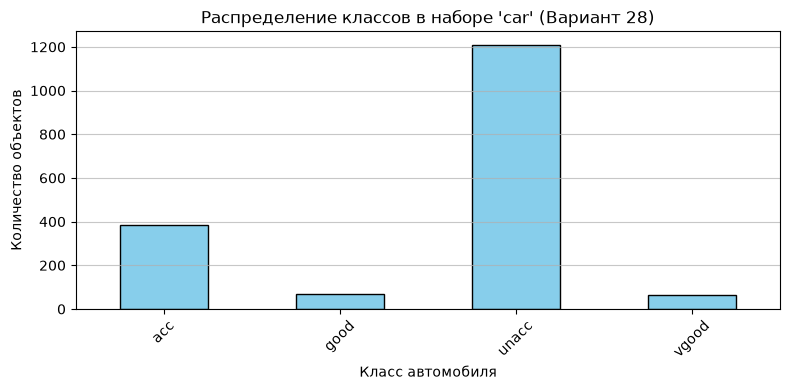


--- Карточка набора данных (для отчета) ---
Номер варианта: 28
Название набора: car
OpenML data_id: 40975
Число объектов: 1728
Число признаков: 6
Числовые признаки: 0
Категориальные признаки: 0
Число классов: 4
Пропуски: 0
Потенциальные сложности: 1) Все или почти все признаки категориальные, требуется One-Hot Encoding. 2) Возможный дисбаланс классов (например, класса 'unacc' значительно больше). 3) Многоклассовая задача (нужен macro-F1).


In [4]:
# ==========================================
# ШАГ 1: Загрузка и первичный анализ данных
# ==========================================
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Настройки варианта
VARIANT = 28
DATA_ID = 40975
RANDOM_STATE = 1000 + VARIANT  # Твой уникальный seed = 1028

print(f"Вариант: {VARIANT}, RANDOM_STATE: {RANDOM_STATE}")

# 2. Загрузка данных (сначала пробуем локальный файл, если нет - качаем из OpenML)
data_dir = Path("ML_Lab1_Datasets")
local_file = data_dir / "variant_28.csv"

if local_file.exists():
    print("Загрузка локальной копии: variant_28.csv")
    # Для набора 'car' целевой столбец обычно называется 'class' или 'target'
    # Прочитаем файл и посмотрим, как он называется
    df = pd.read_csv(local_file)
    # В наборе car целевой столбец часто последний и называется 'class'
    target_col = 'class' if 'class' in df.columns else df.columns[-1]
    X = df.drop(columns=[target_col])
    y = df[target_col]
else:
    print("Локальный файл не найден.")
    exit()

# 3. Первичный анализ
print("\n--- Размерность данных ---")
print(f"Объектов (строк): {X.shape[0]}")
print(f"Признаков (столбцов): {X.shape[1]}")

print("\n--- Первые 5 строк ---")
display(X.head())

print("\n--- Типы данных и пропуски ---")
data_card = pd.DataFrame({
    "Тип данных": X.dtypes.astype(str),
    "Уникальных значений": X.nunique(dropna=True),
    "Пропусков": X.isna().sum(),
    "Доля пропусков (%)": (X.isna().mean() * 100).round(2)
})
display(data_card)

print("\n--- Распределение целевого класса (y) ---")
class_dist = pd.DataFrame({
    "Абсолютная частота": y.value_counts(),
    "Доля (%)": (y.value_counts(normalize=True) * 100).round(2)
})
display(class_dist)

# 4. Визуализация распределения классов
plt.figure(figsize=(8, 4))
y.value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title(f"Распределение классов в наборе 'car' (Вариант {VARIANT})")
plt.xlabel("Класс автомобиля")
plt.ylabel("Количество объектов")
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.7)
plt.tight_layout()
plt.show()

# 5. Заполнение карточки данных (для отчета)
print("\n--- Карточка набора данных (для отчета) ---")
print(f"Номер варианта: {VARIANT}")
print(f"Название набора: car")
print(f"OpenML data_id: {DATA_ID}")
print(f"Число объектов: {X.shape[0]}")
print(f"Число признаков: {X.shape[1]}")
print(f"Числовые признаки: {sum(X.dtypes == 'float64') + sum(X.dtypes == 'int64')}")
print(f"Категориальные признаки: {sum(X.dtypes == 'object') + sum(X.dtypes == 'category')}")
print(f"Число классов: {y.nunique()}")
print(f"Пропуски: {X.isna().sum().sum()}")
print("Потенциальные сложности: 1) Все или почти все признаки категориальные, требуется One-Hot Encoding. 2) Возможный дисбаланс классов (например, класса 'unacc' значительно больше). 3) Многоклассовая задача (нужен macro-F1).")

### 📝 Экспериментальный протокол
- **RANDOM_STATE**: 1028 (гарантирует полную воспроизводимость результатов).
- **Train (80%)**: Используется для обучения моделей и подбора гиперпараметров через кросс-валидацию (CV).
- **CV (StratifiedKFold, 5 фолдов)**: Используется *внутри* Train для честного сравнения моделей без подглядывания в тест.
- **Test (20%)**: "Священная" выборка. К ней нельзя обращаться до самого конца работы (Шаг 6) для финальной оценки. Любое использование Test на ранних этапах = утечка данных (data leakage) и автоматическая переделка.
- **Основная метрика**: `macro-F1` (критически важно для многоклассовой задачи с дисбалансом, как в наборе `car`).

In [5]:
# ==========================================
# ШАГ 2: Разделение данных и кросс-валидация
# ==========================================
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Параметры из Шага 1
VARIANT = 28
RANDOM_STATE = 1000 + VARIANT  # Твой уникальный seed = 1028
TEST_SIZE = 0.20

print(f"RANDOM_STATE для варианта {VARIANT}: {RANDOM_STATE}")

# 2. Разделение на обучающую и тестовую выборки
# stratify=y гарантирует, что пропорции классов (unacc, acc и т.д.) сохранятся в обеих частях
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=TEST_SIZE, 
    stratify=y, 
    random_state=RANDOM_STATE
)

print(f"Данные успешно разделены:")
print(f"   X_train: {X_train.shape[0]} объектов, {X_train.shape[1]} признаков")
print(f"   X_test:  {X_test.shape[0]} объектов, {X_test.shape[1]} признаков")

# 3. Настройка кросс-валидации (применяется ТОЛЬКО к X_train!)
cv = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=RANDOM_STATE
)

print("StratifiedKFold (5 фолдов) настроен и готов к работе.")

RANDOM_STATE для варианта 28: 1028
Данные успешно разделены:
   X_train: 1382 объектов, 6 признаков
   X_test:  346 объектов, 6 признаков
StratifiedKFold (5 фолдов) настроен и готов к работе.


### 📝 Экспериментальный протокол
- **RANDOM_STATE**: 1028 (гарантирует полную воспроизводимость результатов).
- **Train (80%)**: Используется для обучения моделей и подбора гиперпараметров через кросс-валидацию (CV).
- **CV (StratifiedKFold, 5 фолдов)**: Используется *внутри* Train для честного сравнения моделей без подглядывания в тест.
- **Test (20%)**: "Священная" выборка. К ней нельзя обращаться до самого конца работы (Шаг 6) для финальной оценки. Любое использование Test на ранних этапах = утечка данных (data leakage) и автоматическая переделка.
- **Основная метрика**: `macro-F1` (критически важно для многоклассовой задачи с дисбалансом, как в наборе `car`).

In [6]:
# ==========================================
# ШАГ 2: Разделение данных и кросс-валидация
# ==========================================
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Параметры из Шага 1
VARIANT = 28
RANDOM_STATE = 1000 + VARIANT  # Твой уникальный seed = 1028
TEST_SIZE = 0.20

print(f"RANDOM_STATE для варианта {VARIANT}: {RANDOM_STATE}")

# 2. Разделение на обучающую и тестовую выборки
# stratify=y гарантирует, что пропорции классов (unacc, acc и т.д.) сохранятся в обеих частях
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=TEST_SIZE, 
    stratify=y, 
    random_state=RANDOM_STATE
)

print(f"Данные успешно разделены:")
print(f"   X_train: {X_train.shape[0]} объектов, {X_train.shape[1]} признаков")
print(f"   X_test:  {X_test.shape[0]} объектов, {X_test.shape[1]} признаков")

# 3. Настройка кросс-валидации (применяется ТОЛЬКО к X_train!)
cv = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=RANDOM_STATE
)

print("StratifiedKFold (5 фолдов) настроен и готов к работе.")

RANDOM_STATE для варианта 28: 1028
Данные успешно разделены:
   X_train: 1382 объектов, 6 признаков
   X_test:  346 объектов, 6 признаков
StratifiedKFold (5 фолдов) настроен и готов к работе.


### Этап 4: Собственная реализация SGD

Для демонстрации механизма алгоритма необходимо:
1. Свести многоклассовую задачу (4 класса в наборе car) к бинарной схеме "один класс против остальных".
2. Выбрать не более 20 признаков (после one-hot encoding).
3. Сформировать внутреннее разбиение train_demo / val_demo строго из X_train.
4. Реализовать логистическую функцию потерь, градиент и цикл SGD.
5. Исследовать влияние темпа обучения (eta) и силы регуляризации (tau).

In [7]:
# ==========================================
# ШАГ 4: Собственная реализация SGD
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# 1. Сведение многоклассовой задачи к бинарной
# Выбираем класс 'unacc' (самый частый) как положительный (+1), остальные как отрицательные (-1)
positive_class = 'unacc'
y_train_binary = np.where(y_train == positive_class, 1.0, -1.0)

print(f"Бинарная подзадача: класс '{positive_class}' vs остальные")
print(f"Распределение: +1 = {(y_train_binary == 1).sum()}, -1 = {(y_train_binary == -1).sum()}")

# 2. One-hot encoding для категориальных признаков (все признаки в car категориальные)
# Ограничиваем до 20 признаков после кодирования
encoder = OneHotEncoder(sparse_output=False, max_categories=20)
X_train_encoded = encoder.fit_transform(X_train)

# Если признаков получилось больше 20, берем только первые 20
if X_train_encoded.shape[1] > 20:
    X_train_encoded = X_train_encoded[:, :20]
    print(f"Взяты первые 20 признаков из {encoder.get_feature_names_out().shape[0]}")
else:
    print(f"Используем все {X_train_encoded.shape[1]} признаков после one-hot encoding")

# 3. Внутреннее разбиение train_demo / val_demo (строго из X_train!)
X_demo_train, X_demo_val, y_demo_train, y_demo_val = train_test_split(
    X_train_encoded,
    y_train_binary,
    test_size=0.20,
    stratify=y_train_binary,
    random_state=RANDOM_STATE
)

print(f"\nВнутреннее разбиение:")
print(f"  X_demo_train: {X_demo_train.shape[0]} объектов")
print(f"  X_demo_val: {X_demo_val.shape[0]} объектов")

# 4. Масштабирование (fit только на train_demo!)
scaler_demo = StandardScaler()
X_demo_train = scaler_demo.fit_transform(X_demo_train)
X_demo_val = scaler_demo.transform(X_demo_val)

print("Масштабирование выполнено (fit только на train_demo)")

Бинарная подзадача: класс 'unacc' vs остальные
Распределение: +1 = 968, -1 = 414
Взяты первые 20 признаков из 21

Внутреннее разбиение:
  X_demo_train: 1105 объектов
  X_demo_val: 277 объектов
Масштабирование выполнено (fit только на train_demo)


In [8]:
# ==========================================
# Функции для собственной реализации SGD
# ==========================================

def sigmoid(z):
    """Сигмоида с защитой от переполнения"""
    z = np.clip(np.asarray(z, dtype=float), -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z))

def mean_logistic_loss(X, y_pm, w, b):
    """Средняя логистическая функция потерь"""
    margins = y_pm * (X @ w + b)
    return np.mean(np.logaddexp(0.0, -margins))

def train_logreg_sgd(X_train, y_train_pm, X_val, y_val_pm, 
                     eta=0.01, tau=1e-4, epochs=50, random_state=42):
    """
    Обучение логистической регрессии методом SGD
    
    Параметры:
    - eta: темп обучения (learning rate)
    - tau: коэффициент L2-регуляризации
    - epochs: число эпох
    """
    rng = np.random.default_rng(random_state)
    
    # Инициализация весов
    w = np.zeros(X_train.shape[1], dtype=float)
    b = 0.0
    
    # История для графиков
    history = {"train_loss": [], "val_loss": [], "weight_norm": []}
    
    for epoch in range(epochs):
        # Случайное перемешивание объектов в начале каждой эпохи
        for i in rng.permutation(len(X_train)):
            x_i = X_train[i]
            y_i = y_train_pm[i]
            
            # Вычисление отступа
            margin = y_i * (x_i @ w + b)
            
            # Градиент логистической потери
            factor = -y_i * sigmoid(-margin)
            
            # Градиент с L2-регуляризацией (b не регуляризуется)
            grad_w = factor * x_i + tau * w
            grad_b = factor
            
            # Шаг SGD
            w -= eta * grad_w
            b -= eta * grad_b
        
        # Сохранение метрик после каждой эпохи
        history["train_loss"].append(mean_logistic_loss(X_train, y_train_pm, w, b))
        history["val_loss"].append(mean_logistic_loss(X_val, y_val_pm, w, b))
        history["weight_norm"].append(np.linalg.norm(w))
    
    return w, b, pd.DataFrame(history)

print("Функции для SGD определены")

Функции для SGD определены


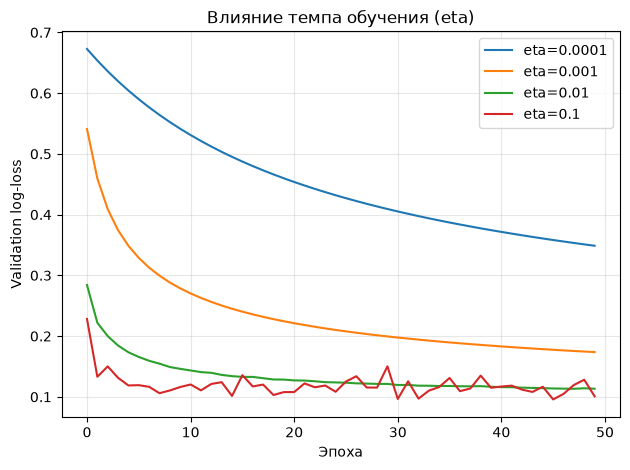


Результаты для разных eta:


,final_train_loss,final_val_loss,weight_norm
0.0001,0.3330,0.3487,1.1367
0.0010,0.1573,0.1737,3.1907
0.0100,0.1065,0.1133,6.4138
0.1000,0.1067,0.1009,9.3607



Лучшее eta по validation loss: 0.1


In [10]:
# ==========================================
# Исследование влияния темпа обучения (eta)
# ==========================================

eta_values = [0.0001, 0.001, 0.01, 0.1]
eta_runs = {}

for eta in eta_values:
    _, _, history = train_logreg_sgd(
        X_demo_train, y_demo_train,
        X_demo_val, y_demo_val,
        eta=eta, tau=1e-4, epochs=50,
        random_state=RANDOM_STATE
    )
    eta_runs[eta] = history
    
    plt.plot(history["val_loss"], label=f"eta={eta}")

plt.xlabel("Эпоха")
plt.ylabel("Validation log-loss")
plt.title("Влияние темпа обучения (eta)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Таблица с итоговыми значениями
eta_result = pd.DataFrame({
    eta: {
        "final_train_loss": h["train_loss"].iloc[-1],
        "final_val_loss": h["val_loss"].iloc[-1],
        "weight_norm": h["weight_norm"].iloc[-1]
    }
    for eta, h in eta_runs.items()
}).T

print("\nРезультаты для разных eta:")
display(eta_result.round(4))

# Выбираем лучшее eta по validation loss
best_eta = eta_result["final_val_loss"].idxmin()
print(f"\nЛучшее eta по validation loss: {best_eta}")

Результаты для разных tau:


,tau,val_loss,weight_norm
0,0.0000,0.0996,10.2522
1,0.0001,0.1009,9.3607
2,0.0100,0.1786,3.4229


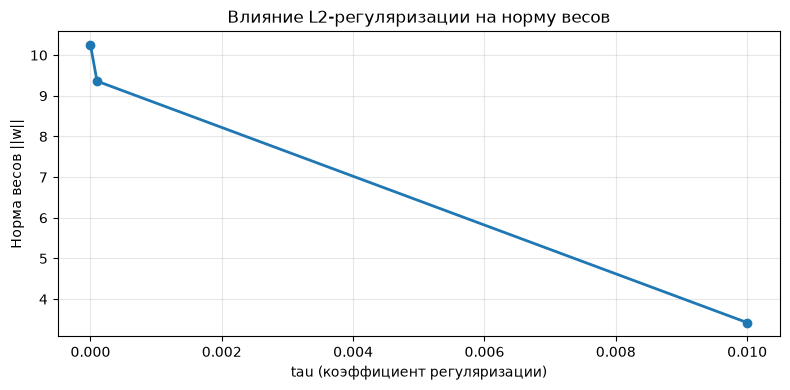


Вывод: при увеличении tau норма весов уменьшается, что предотвращает переобучение.


In [11]:
# ==========================================
# Исследование влияния регуляризации (tau)
# ==========================================

tau_values = [0.0, 1e-4, 1e-2]
tau_result = []

for tau in tau_values:
    w_sgd, b_sgd, history = train_logreg_sgd(
        X_demo_train, y_demo_train,
        X_demo_val, y_demo_val,
        eta=float(best_eta), tau=tau, epochs=50,
        random_state=RANDOM_STATE
    )
    
    tau_result.append({
        "tau": tau,
        "val_loss": history["val_loss"].iloc[-1],
        "weight_norm": np.linalg.norm(w_sgd)
    })

tau_result = pd.DataFrame(tau_result)
print("Результаты для разных tau:")
display(tau_result.round(4))

# График зависимости нормы весов от tau
plt.figure(figsize=(8, 4))
plt.plot(tau_result["tau"], tau_result["weight_norm"], marker='o', linewidth=2)
plt.xlabel("tau (коэффициент регуляризации)")
plt.ylabel("Норма весов ||w||")
plt.title("Влияние L2-регуляризации на норму весов")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nВывод: при увеличении tau норма весов уменьшается, что предотвращает переобучение.")